In [1]:
import glob
import os

import numpy as np
import cv2
import matplotlib.pyplot as plt
from tqdm import tqdm
from ultralytics import YOLO

import sys
sys.path.append("../../researches/objectdetectionmetrics/")
from metricsevaluator import MetricsEvaluator

In [2]:
def process_prediction(predictions):
    labels = predictions.boxes.cls.cpu().numpy()[predictions.boxes.cls.cpu().numpy() < 2]
    confidences = predictions.boxes.conf.cpu().numpy()[predictions.boxes.cls.cpu().numpy() < 2]
    boxes = predictions.boxes.xywhn.cpu().numpy()[predictions.boxes.cls.cpu().numpy() < 2]
    
    return os.path.basename(predictions.path).split(".")[0], labels, confidences, boxes

In [27]:
# font 
font = cv2.FONT_HERSHEY_SIMPLEX 
  
# fontScale 
fontScale = 0.35
  
# Line thickness of 2 px 
thickness = 1

In [39]:
INPUT_WIDTH = 640
INPUT_HEIGHT = 640

base_pth = "results"
model_name = "v2_batch6_merged_furniture_table_chair_model_s"

data = "datasets/v2_batch6/merged_furniture_table_chair"

thres = 0.35
iou_thres = 0.45

model = YOLO(os.path.join(base_pth, model_name, "weights/best.pt"))
predictions = model.predict(os.path.join(data, "images", "val"), conf=thres, iou=iou_thres, verbose=False)

classes = ["chair", "table"]

colors = {
    "chair": (0, 255, 0),
    "table": (128, 0, 0)
}

os.makedirs("val_viz", exist_ok=True)
for pred in tqdm(predictions):
    img = pred.plot()  # This plots the detections on the image
    img_h, img_w, _ = img.shape

    idx = os.path.basename(os.path.splitext(pred.path)[0])

    # init evaluator
    evaluator = MetricsEvaluator(
        is_relative_coordinates=True,
        is_xywh_coordinates=True,
        img_size=(INPUT_WIDTH, INPUT_HEIGHT),
        outpath="."
    )

    with open(os.path.join(data, "labels", "val", f"{idx}.txt"), "rt") as f:
        lines = f.readlines()

    for line in lines:
        c, x_c, y_c, w, h = [float(i) for i in line[:-1].split()][:5]
        if c > 1:
            continue
        
        evaluator.add_gt_box(
            img_path=idx,
            class_name=classes[int(c)],
            bbox=[x_c, y_c, w, h]
        )
        
        p1 = [int((x_c - w / 2) * img_w), int((y_c - h / 2) * img_h)]
        p2 = [int((x_c + w / 2) * img_w), int((y_c + h / 2) * img_h)]
        cv2.rectangle(img, p1, p2, colors[classes[int(c)]], 2)

    img_name, labels, confidences, boxes = process_prediction(pred)
    for box, cl, conf in zip(boxes, labels, confidences):
        x_c = box[0] + box[2] / 2
        y_c = box[1] + box[3] / 2
        evaluator.add_det_box(
            img_path=img_name,
            class_name=classes[int(cl)],
            bbox=box,
            confidence=conf
        )

    results = evaluator.eval_conf_vals(0.5)

    cv2.rectangle(img, [0, 0], [300, 35], (255, 255, 255), -1)

    for i, result in enumerate(results):
        precision = result["total TP"] / (result["total TP"] + result["total FP"])
        recall = result["total TP"] / (result["total positives"])

        f_score = 2 * precision * recall / (precision + recall)
        s = f"{result['class']}: P = {precision:.02f}. R = {recall:.02f}. F1 = {f_score:.02f}. AP = {result['AP']:.02f}"
        # print(s)
        cv2.putText(img, s, [5, 15 * (1 + i)], font, fontScale, (0, 0, 0), thickness, cv2.LINE_AA) 


    cv2.imwrite(f"val_viz/{idx}.jpg", img)
    # break
    # plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

  0%|          | 0/292 [00:00<?, ?it/s]/tmp/ipykernel_3723493/1493382207.py:74: RuntimeWarning: invalid value encountered in scalar divide
  f_score = 2 * precision * recall / (precision + recall)
/tmp/ipykernel_3723493/1493382207.py:71: RuntimeWarning: invalid value encountered in scalar divide
  precision = result["total TP"] / (result["total TP"] + result["total FP"])
 10%|▉         | 29/292 [00:00<00:05, 49.16it/s]/tmp/ipykernel_3723493/1493382207.py:72: RuntimeWarning: invalid value encountered in scalar divide
  recall = result["total TP"] / (result["total positives"])
100%|██████████| 292/292 [00:06<00:00, 45.97it/s]


In [30]:
INPUT_WIDTH = 640
INPUT_HEIGHT = 640

base_pth = "results"
model_name = "v2_batch6_merged_furniture_table_chair_model_s"

data = "datasets/v2_batch6/merged_furniture_table_chair"

thres = 0.35
iou_thres = 0.45

model = YOLO(os.path.join(base_pth, model_name, "weights/best.pt"))
predictions = model.predict(os.path.join(data, "images", "val"), conf=thres, iou=iou_thres, verbose=False)

classes = ["chair", "table"]

# init evaluator
evaluator = MetricsEvaluator(
    is_relative_coordinates=True,
    is_xywh_coordinates=True,
    img_size=(INPUT_WIDTH, INPUT_HEIGHT),
    outpath="."
)

for label_pth in os.listdir(os.path.join(data, "labels", "val")):
    img_name = label_pth.split(".")[0]

    with open(os.path.join(data, "labels", "val", label_pth), "rt") as f:
        lines = f.readlines()
    
    for line in lines:
        c, x_c, y_c, w, h = [float(i) for i in line[:-1].split()][:5]
        if c > 1:
            continue
        
        evaluator.add_gt_box(
            img_path=img_name,
            class_name=classes[int(c)],
            bbox=[x_c, y_c, w, h]
        )
    # break

for img_predictions in tqdm(predictions):
    img_name, labels, confidences, boxes = process_prediction(img_predictions)
    for box, cl, conf in zip(boxes, labels, confidences):
        x_c = box[0] + box[2] / 2
        y_c = box[1] + box[3] / 2
        evaluator.add_det_box(
            img_path=img_name,
            class_name=classes[int(cl)],
            bbox=box,
            confidence=conf
        )

results = evaluator.eval_conf_vals(0.5)

for result in results:
    precision = result["total TP"] / (result["total TP"] + result["total FP"])
    recall = result["total TP"] / (result["total positives"])

    f_score = 2 * precision * recall / (precision + recall)
    print(f"{result['class']}: P = {precision:.03f}. R = {recall:.03f}. F1 = {f_score:.03f}. AP = {result['AP']:.03f}")


100%|██████████| 292/292 [00:00<00:00, 869.09it/s]


chair: P = 0.871. R = 0.749. F1 = 0.806. AP = 0.726
table: P = 0.879. R = 0.710. F1 = 0.786. AP = 0.681


In [4]:
INPUT_WIDTH = 640
INPUT_HEIGHT = 640

base_pth = "results"
model_name = "v2_batch6_merged_furniture_table_chair_model_s"

data = "datasets/v2_batch6/merged_furniture_table_chair_gray"

thres = 0.35
iou_thres = 0.45

model = YOLO(os.path.join(base_pth, model_name, "weights/best.pt"))
predictions = model.predict(os.path.join(data, "images", "val"), conf=thres, iou=iou_thres, verbose=False)

classes = ["chair", "table"]

# init evaluator
evaluator = MetricsEvaluator(
    is_relative_coordinates=True,
    is_xywh_coordinates=True,
    img_size=(INPUT_WIDTH, INPUT_HEIGHT),
    outpath="."
)

for label_pth in os.listdir(os.path.join(data, "labels", "val")):
    img_name = label_pth.split(".")[0]

    with open(os.path.join(data, "labels", "val", label_pth), "rt") as f:
        lines = f.readlines()
    
    for line in lines:
        c, x_c, y_c, w, h = [float(i) for i in line[:-1].split()][:5]
        if c > 1:
            continue
        
        evaluator.add_gt_box(
            img_path=img_name,
            class_name=classes[int(c)],
            bbox=[x_c, y_c, w, h]
        )
    # break

for img_predictions in tqdm(predictions):
    img_name, labels, confidences, boxes = process_prediction(img_predictions)
    for box, cl, conf in zip(boxes, labels, confidences):
        x_c = box[0] + box[2] / 2
        y_c = box[1] + box[3] / 2
        evaluator.add_det_box(
            img_path=img_name,
            class_name=classes[int(cl)],
            bbox=box,
            confidence=conf
        )

results = evaluator.eval_conf_vals(0.5)

for result in results:
    precision = result["total TP"] / (result["total TP"] + result["total FP"])
    recall = result["total TP"] / (result["total positives"])

    f_score = 2 * precision * recall / (precision + recall)
    print(f"{result['class']}: P = {precision:.03f}. R = {recall:.03f}. F1 = {f_score:.03f}. AP = {result['AP']:.03f}")


100%|██████████| 292/292 [00:00<00:00, 863.03it/s]


chair: P = 0.869. R = 0.751. F1 = 0.806. AP = 0.730
table: P = 0.877. R = 0.700. F1 = 0.779. AP = 0.670


In [6]:
data = "datasets/v2_batch6/merged_furniture_table_chair_gray"
img_folder = os.path.join(data, "images", "val")
tst_img_paths = sorted([os.path.join(img_folder, i) for i in os.listdir(img_folder)])
len(tst_img_paths)

292

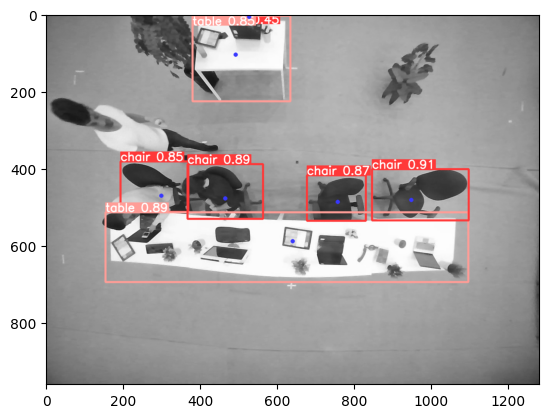

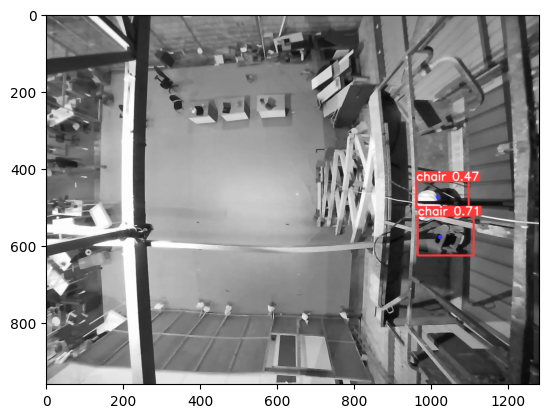

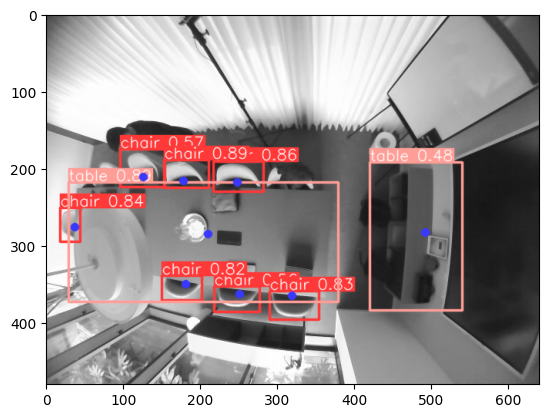

In [15]:
for img_pth in tst_img_paths[:3]:
    detections = model(img_pth, classes=[0, 1], conf=0.35, iou=0.45, device=1)

    img = detections[0].plot()  # This plots the detections on the image
    plt.figure()
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))